# Vegetable Classification

## Project Overview

The goal of this project is to build an image classification model that identifies which vegetable is shown in a picture.

This project uses the Vegetable Image Dataset. For more information, [click here](https://www.kaggle.com/datasets/misrakahmed/vegetable-image-dataset).

| Property | Value |
|---|---|
| Classes | 15 (Bean, Bitter Gourd, Bottle Gourd, Brinjal, Broccoli, Cabbage, Capsicum, Carrot, Cauliflower, Cucumber, Papaya, Potato, Pumpkin, Radish, Tomato) |
| Images | 21,000 (224 x 224 RGB) |
| Splits | 15,000 train / 3,000 validation / 3,000 test |

In this project, we are going to use the following approach:

1. **DINOv2 (Feature Extraction)**: DINOv2 is a Vision Transformer trained with self-supervised learning on a huge image collection. Its embeddings already describe objects very well, so we keep the whole backbone **frozen** and use it only as a feature extractor.
2. **Linear Classifier (Linear Probing)**: We train a small classifier head (Dropout + Linear) on top of the saved embeddings. Because the embeddings are computed only once, training takes seconds instead of minutes.

The objective is to understand how to reuse a strong pretrained model efficiently. We also use our own utility file (`pytorch_utils`) to reduce repetition and the length of the code.

## Importing Libraries and Setting Up Environment

In [1]:
## Pytorch
import torch
from torch import nn
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader

## Torchvision
import torchvision
from torchvision.transforms import v2

## TorchSummary
from torchinfo import summary

## YOLO
try:
    from transformers import AutoImageProcessor, AutoModel ## HuggingFace Transformers
except:
    print("[INFO] Couldn't find HuggingFace Transformers... installing it.")
    !pip install -U transformers
    from transformers import AutoImageProcessor, AutoModel

## Import Utility Function
from pytorch_utils import train_model, test_model, eval_model, accuracy_fn, create_datasets, create_dataloaders, fit_model, plot_history

## TimeIT
from timeit import default_timer as timer

## Plotting
import matplotlib.pyplot as plt

## Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Classification Report
from ignite.engine import Engine
from ignite.metrics import ClassificationReport

## Path
from pathlib import Path

## Pillow
from PIL import Image

## tqdm
from tqdm.auto import tqdm

## Device SetUp
device = "cuda" if torch.cuda.is_available() else "cpu"

## Checking Version
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}\nDevice: {device}")

(path: str, loader: Callable = <function default_loader at 0x7cf5b8057ce0>, split: str = 'train', train_transform=None, eval_transform=None)
PyTorch version: 2.11.0+cu128
torchvision version: 0.26.0+cu128
Device: cuda


## Preprocessing

DINOv2 expects 224 x 224 images normalized with the ImageNet mean and standard deviation. The pipeline below resizes first, then converts to a float tensor and normalizes.

We do **not** use random augmentation here. The embeddings are computed only once and then reused for every epoch, so random augmentation would be frozen into the saved features and would not add variety.

In [2]:
tf = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean= (0.485, 0.456, 0.406),
        std= (0.229, 0.224, 0.225)
    ),
    v2.Resize((224, 224))
])

## Load Images into Datasets

Our data is stored in folders. For example, the train folder contains one sub-folder per vegetable, and each of those contains the images of that vegetable. We convert this structure into the `torchvision.datasets` format with the help of `ImageFolder`. For more information, please visit this [page](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html).

We already stored the `ImageFolder` setup in our utility file, and it can be called with the `create_datasets()` function. This function requires:

1. Path of your dataset
2. `split`, which is one of `train`, `val`, `test` or `trainval`
3. `train_transform` and/or `eval_transform`. Use the one that fits the split; `eval_transform` is used for both val and test.

In [3]:
# Path of our Dataset
PATH = Path("/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images")

## Load Train Data 
train_data = create_datasets(
    path=PATH,
    split="train",
    train_transform=tf
)

## Load Val Data 
val_data = create_datasets(
    path=PATH,
    split="val",
    eval_transform=tf
)

## Load Test Data 
test_data = create_datasets(
    path=PATH,
    split="test",
    eval_transform=tf
)

## Load TrainVal Data 
trainval_data = create_datasets(
    path=PATH,
    split="trainval",
    train_transform=tf,
    eval_transform=tf
)

## Checking The Length of Data
total = len(train_data) + len(val_data) + len(test_data)
len(train_data), len(val_data), len(test_data), len(trainval_data), total

(15000, 3000, 3000, 18000, 21000)

## Understanding Data

Let's understand the data and check the following things:

1. Classes
2. Image and its type
3. Label
4. Shape of the image

In [4]:
## Checking Class Names and how many are those
class_names = train_data.classes
class_names, len(class_names)

(['Bean',
  'Bitter_Gourd',
  'Bottle_Gourd',
  'Brinjal',
  'Broccoli',
  'Cabbage',
  'Capsicum',
  'Carrot',
  'Cauliflower',
  'Cucumber',
  'Papaya',
  'Potato',
  'Pumpkin',
  'Radish',
  'Tomato'],
 15)

In [5]:
## Load Image and Label of any random image from train Data

image, label = train_data[50]
image, class_names[label]

(Image([[[-1.0390, -0.9877, -0.9020,  ..., -0.3369, -0.2856, -0.2856],
         [-0.9534, -0.9534, -0.9877,  ..., -0.2856, -0.2856, -0.2856],
         [-0.6623, -0.7650, -0.8849,  ..., -0.3027, -0.3027, -0.2513],
         ...,
         [ 0.6392,  0.5878,  0.6392,  ...,  0.2282,  0.2282,  0.1083],
         [ 0.6734,  0.6221,  0.6221,  ...,  0.3309,  0.2967,  0.2111],
         [ 0.7248,  0.6734,  0.6392,  ...,  0.3994,  0.3309,  0.2453]],
 
        [[-0.3025, -0.2500, -0.2500,  ...,  0.5553,  0.5203,  0.5203],
         [-0.2150, -0.2500, -0.3375,  ...,  0.6078,  0.5553,  0.5553],
         [ 0.0476, -0.0574, -0.2325,  ...,  0.5903,  0.5903,  0.6429],
         ...,
         [ 1.4482,  1.4482,  1.4832,  ...,  1.1681,  1.1681,  1.0630],
         [ 1.4832,  1.4307,  1.4132,  ...,  1.1331,  1.1155,  1.0280],
         [ 1.5007,  1.4482,  1.4482,  ...,  1.1856,  1.0805,  0.9930]],
 
        [[-1.1596, -1.1073, -1.0550,  ..., -0.9156, -0.8807, -0.8807],
         [-1.0724, -1.0898, -1.1421,  ..., 

In [6]:
type(image), image.shape, type(label)

(torchvision.tv_tensors._image.Image, torch.Size([3, 224, 224]), int)

## Creating DataLoaders

DataLoaders are part of `torch.utils.data`. For more information, click [here](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html). We use our custom `create_dataloaders()` utility function to create them easily.

These image dataloaders are only needed **once**, to extract the embeddings.

In [7]:
## Since we're going to create dataloader for trainval_data let's confirm type of data 
type(trainval_data), type(train_data)

(torch.utils.data.dataset.ConcatDataset,
 torchvision.datasets.folder.ImageFolder)

In [8]:
torch.manual_seed(42)
train_dataloader, val_dataloader, test_dataloader = create_dataloaders(train_data, 
                                                                       val_data, 
                                                                       test_data, 
                                                                       batch_size=32, 
                                                                       num_workers=0)

train_dataloader: 469 batches of 32
val_dataloader: 94 batches of 32
test_dataloader: 94 batches of 32


In [9]:
trainval_dataloader = create_dataloaders(trainval_data, 
                                               batch_size=32, 
                                               num_workers=3)

train_dataloader: 563 batches of 32


In [10]:
image, label = next(iter(trainval_dataloader))
image, label

(tensor([[[[-1.6384, -1.6384, -1.6384,  ...,  1.2043,  0.8789,  0.5536],
           [-1.6042, -1.6042, -1.6042,  ...,  0.9132,  0.4337,  0.1768],
           [-1.6042, -1.6042, -1.6042,  ...,  0.5193,  0.2796,  0.3652],
           ...,
           [-0.9020, -0.8335, -0.7650,  ..., -0.6965, -0.3027,  0.0056],
           [-1.5528, -1.3130, -1.1075,  ..., -0.8335, -0.4397, -0.1999],
           [-1.6042, -1.3815, -1.3473,  ..., -0.9020, -0.5424, -0.4054]],
 
          [[-1.7206, -1.7206, -1.7206,  ..., -0.0399, -0.4426, -0.7927],
           [-1.6856, -1.6856, -1.6856,  ..., -0.4076, -0.9328, -1.2129],
           [-1.6856, -1.6856, -1.6856,  ..., -0.9153, -1.1954, -1.1253],
           ...,
           [-0.4426, -0.4076, -0.3550,  ...,  0.0126,  0.5203,  0.8880],
           [-1.0203, -0.7577, -0.6352,  ..., -0.1625,  0.3277,  0.6429],
           [-1.0028, -0.8102, -0.8102,  ..., -0.2325,  0.2227,  0.4328]],
 
          [[-1.5256, -1.5256, -1.5256,  ..., -0.7413, -0.8458, -1.0724],
           [-

In [11]:
images, targets = next(iter(train_dataloader))

print(type(images))
print(images.shape)
print(images.dtype)
print(type(targets))
print(targets.shape)

<class 'torch.Tensor'>
torch.Size([32, 3, 224, 224])
torch.float32
<class 'torch.Tensor'>
torch.Size([32])


## Preparing DINOv2 Model

Model page: [facebook/dinov2-base](https://huggingface.co/facebook/dinov2-base)

To prepare the model, we do the following things:

1. Load the pretrained DINOv2 backbone
2. Freeze **all** of its parameters

Freezing is important here. We are not fine-tuning the backbone; we only use it to turn every image into a 768-dimensional embedding. The only part we train later is the small classifier head.

In [12]:
# Load the Pretrained Model
model = AutoModel.from_pretrained("facebook/dinov2-base", device_map="auto")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

In [13]:
type(model)

transformers.models.dinov2.modeling_dinov2.Dinov2Model

In [14]:
model

Dinov2Model(
  (embeddings): Dinov2Embeddings(
    (patch_embeddings): Dinov2PatchEmbeddings(
      (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (encoder): Dinov2Encoder(
    (layer): ModuleList(
      (0-11): 12 x Dinov2Layer(
        (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (attention): Dinov2Attention(
          (attention): Dinov2SelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
          )
          (output): Dinov2SelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
        )
        (layer_scale1): Dinov2LayerScale()
        (drop_path): Identity()
        (norm2): LayerNorm((768,), eps=1e-06,

In [15]:
# Print all top-level attributes/modules of your model
print("Top-level components of your model:")
for name, module in model.named_children():
    print(f" • model.{name} -> {type(module)}")

Top-level components of your model:
 • model.embeddings -> <class 'transformers.models.dinov2.modeling_dinov2.Dinov2Embeddings'>
 • model.encoder -> <class 'transformers.models.dinov2.modeling_dinov2.Dinov2Encoder'>
 • model.layernorm -> <class 'torch.nn.modules.normalization.LayerNorm'>


In [16]:
# Freeze everything in the backbone (embeddings + transformer layers)
for param in model.parameters():
    param.requires_grad = False

# Unfreeze only the classification head
for param in model.layernorm.parameters():
    param.requires_grad = True

print("Classifier parameters are now trainable:", any(p.requires_grad for p in model.layernorm.parameters()))

Classifier parameters are now trainable: True


In [17]:
# Check if backbone parameters are frozen (should be True)
backbone_frozen = all(not p.requires_grad for p in model.parameters())
print(f"Is the backbone fully frozen? {backbone_frozen}")

# Check if classifier parameters are trainable (should be True)
classifier_trainable = all(p.requires_grad for p in model.layernorm.parameters())
print(f"Is the classifier fully trainable? {classifier_trainable}")

Is the backbone fully frozen? False
Is the classifier fully trainable? True


In [18]:
model.parameters, model.layernorm.parameters
    

(<bound method Module.parameters of Dinov2Model(
   (embeddings): Dinov2Embeddings(
     (patch_embeddings): Dinov2PatchEmbeddings(
       (projection): Conv2d(3, 768, kernel_size=(14, 14), stride=(14, 14))
     )
     (dropout): Dropout(p=0.0, inplace=False)
   )
   (encoder): Dinov2Encoder(
     (layer): ModuleList(
       (0-11): 12 x Dinov2Layer(
         (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
         (attention): Dinov2Attention(
           (attention): Dinov2SelfAttention(
             (query): Linear(in_features=768, out_features=768, bias=True)
             (key): Linear(in_features=768, out_features=768, bias=True)
             (value): Linear(in_features=768, out_features=768, bias=True)
           )
           (output): Dinov2SelfOutput(
             (dense): Linear(in_features=768, out_features=768, bias=True)
             (dropout): Dropout(p=0.0, inplace=False)
           )
         )
         (layer_scale1): Dinov2LayerScale()
         (drop_path

## Extract Embeddings from DataLoader

First, let's look at what the model returns for a single batch:

- `last_hidden_state`: one vector for every image patch (plus the CLS token)
- `pooler_output`: one vector for the whole image (the normalized CLS token). **This is the embedding we use.**

In [19]:
## First we're gonna extract only one embedding
image, label = next(iter(train_dataloader))

# @torch.no_grad()
model.eval()
image = image.to(device, non_blocking=True)
output = model(image)
output

BaseModelOutputWithPooling(last_hidden_state=tensor([[[ 1.8085e+00,  8.8661e-01,  3.5294e+00,  ..., -1.4671e+00,
          -2.6664e+00,  1.2782e+00],
         [-9.4975e-01, -3.5278e-01,  1.0657e+00,  ..., -3.9734e-01,
          -1.6864e+00, -2.0089e+00],
         [-2.2591e+00, -1.7607e+00, -8.6159e-01,  ..., -2.2542e+00,
          -8.1624e-01,  1.4423e+00],
         ...,
         [ 3.2241e-01,  1.7043e+00,  2.7526e+00,  ...,  2.3273e+00,
          -1.7223e+00,  1.6064e+00],
         [ 2.3514e+00, -9.3300e-01,  1.9428e+00,  ...,  5.3886e-01,
           3.5680e-01,  5.0727e-01],
         [ 1.6459e+00, -1.1508e+00,  1.7032e+00,  ..., -2.3400e-01,
          -5.3675e-01,  3.8751e-02]],

        [[ 2.7595e+00,  3.5166e-02, -2.2218e+00,  ..., -1.0661e+00,
           1.0173e+00, -2.1734e+00],
         [-1.5966e+00, -1.0865e+00, -5.2735e-01,  ..., -3.8868e-01,
          -6.5638e-01, -1.3680e+00],
         [-2.1064e-01, -4.1005e-01,  7.3615e-01,  ...,  4.0442e-01,
          -1.2199e+00, -2.2361e

In [20]:
output.last_hidden_state.shape, image.shape, output.pooler_output.shape

(torch.Size([32, 257, 768]),
 torch.Size([32, 3, 224, 224]),
 torch.Size([32, 768]))

### Extraction Function

This function passes every batch through the frozen backbone and collects the embeddings together with their labels.

In [21]:
@torch.no_grad()
def extract_embeddings(model, dataloader, device):
    
    model.eval()
    
    embeddings = []
    labels = []
    
    for images, targets in tqdm(dataloader):
    
        images = images.to(device, non_blocking=True)
    
        # Extract DINOv2 features
        features = model(pixel_values=images)
        # CLS token embeddings
        batch_embeddings = features.pooler_output
    
        embeddings.append(batch_embeddings.cpu())
        labels.append(targets.cpu())
    
        embeddings = torch.cat(embeddings, dim=0)
        labels = torch.cat(labels, dim=0)
    
    return embeddings, labels

### Load Saved Embeddings or Create Them

Extracting embeddings for 21,000 images takes a while, so we try to load a previously saved file first. If it does not exist, we extract the embeddings and save them for the next run.

In [22]:
file_path = Path("/kaggle/input/datasets/purabsingla/dinov2-vegetables-embeddings/dinov2_vegetables_embeddings.pt")

if file_path.exists():
    data = torch.load(file_path, map_location="cpu", weights_only=True)
    print(f"Loaded saved embeddings from: {file_path}")

else:
    print("[INFO] Saved embeddings not found... extracting them now.")
    data = {}
    for split, loader in {
        "train":    train_dataloader,
        "val":      val_dataloader,
        "test":     test_dataloader,
        "trainval": trainval_dataloader,
    }.items():
        print(f"------ {split} embeddings ------")
        emb, lbl = extract_embeddings(model, loader, device)
        data[split] = {"embeddings": emb, "labels": lbl}

    ## Saving Features / Embeddings
    torch.save(data, "dinov2_vegetables_embeddings.pt")
    print("Embeddings saved to: dinov2_vegetables_embeddings.pt")

Loaded saved embeddings from: /kaggle/input/datasets/purabsingla/dinov2-vegetables-embeddings/dinov2_vegetables_embeddings.pt


In [23]:
train_dataset = TensorDataset(
    data["train"]["embeddings"],
    data["train"]["labels"]
)

val_dataset = TensorDataset(
    data["val"]["embeddings"],
    data["val"]["labels"]
)

test_dataset = TensorDataset(
    data["test"]["embeddings"],
    data["test"]["labels"]
)

In [24]:
len(train_dataset), len(train_dataloader)

(15000, 469)

## Creating Datasets and DataLoaders for Embeddings

Now every image is just a vector of 768 numbers, so we wrap the tensors in `TensorDataset` and create new dataloaders. Since there is no image decoding anymore, `num_workers=0` is the fastest option.

In [25]:
torch.manual_seed(42)
train_embloader, val_embloader, test_embloader = create_dataloaders(train_dataset, 
                                                                       val_dataset, 
                                                                       test_dataset, 
                                                                       batch_size=32, 
                                                                       num_workers=4)

train_dataloader: 469 batches of 32
val_dataloader: 94 batches of 32
test_dataloader: 94 batches of 32


## Creating the Classifier

The classifier head is deliberately simple: **Dropout** (to reduce overfitting) followed by one **Linear** layer that maps the 768 embedding features to our 15 classes.

In [26]:
cls = model.layernorm.normalized_shape[0]
model.config.hidden_size

768

In [27]:
class Classifier(nn.Module):
    def __init__(self, input_features:int, num_classes:int, dropout:float):
        super().__init__()
        
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(input_features, num_classes)
        )

    def forward(self, x):
        return self.fc(x)

In [28]:
classifier = Classifier(
    input_features=cls,
    num_classes=len(class_names),
    dropout=0.3
).to(device)

cmp_mdl = torch.compile(classifier)
cmp_mdl

OptimizedModule(
  (_orig_mod): Classifier(
    (fc): Sequential(
      (0): Dropout(p=0.3, inplace=False)
      (1): Linear(in_features=768, out_features=15, bias=True)
    )
  )
)

## Evaluation Helpers

We will evaluate the model twice (validation, then test). Instead of copying the same code each time, we define two small helper functions: one for the **confusion matrix** and one for the **classification report**.

In [29]:
def print_train_time(
    start: float,
    end: float,
    device: torch.device= None
):
    total_time = end - start
    print(f"Time Taken on {device} device is {total_time:.3f} seconds")

## Creating Loss Function and Optimizer

We create the loss function and the optimizer:

1. `Loss Fn` calculates how wrong the model's predictions are compared to the true answers.
2. `Optimizer` updates the weights of the classifier to minimize that error.

In [30]:
## Loss Function
loss_fn = nn.CrossEntropyLoss()

## Optimizer
optimizer = AdamW(
    lr= 1e-4,
    params= cmp_mdl.parameters()
)

## Training and Validation Loop

We now train the classifier with the train data and evaluate it with the validation data. The `fit_model()` utility returns the training history and the weights of the best epoch.

In [31]:
## Using pytorch_utils fit_model method to train our loop
history, best_model_state = fit_model(model=cmp_mdl,
                                      train_model=train_model,
                                      test_model=test_model,
                                      train_dataloader=train_embloader,
                                      test_dataloader=val_embloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      accuracy_fn=accuracy_fn,
                                      epochs=20,
                                      device=device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1
----------


  0%|          | 0/469 [00:00<?, ?it/s]

W1105 12:52:23.130000 48 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


Train Loss = 0.50228 || Train Accuracy = 88.13%
Test loss: 0.05937 | Test accuracy: 99.57%

🔥 New best model! Accuracy: 99.57%
Epoch 2
----------


  0%|          | 0/469 [00:00<?, ?it/s]

... (33 outputs left out)

  0%|          | 0/469 [00:00<?, ?it/s]

Train Loss = 0.00074 || Train Accuracy = 100.00%
Test loss: 0.00154 | Test accuracy: 99.93%

Epoch 20
----------


  0%|          | 0/469 [00:00<?, ?it/s]

Train Loss = 0.00059 || Train Accuracy = 100.00%
Test loss: 0.00137 | Test accuracy: 99.97%

Time Taken on cuda device is 49.222 seconds


## Plotting Curves of Train and Validation Accuracy and Loss

This helps us check the results clearly and see whether the model is overfitting.

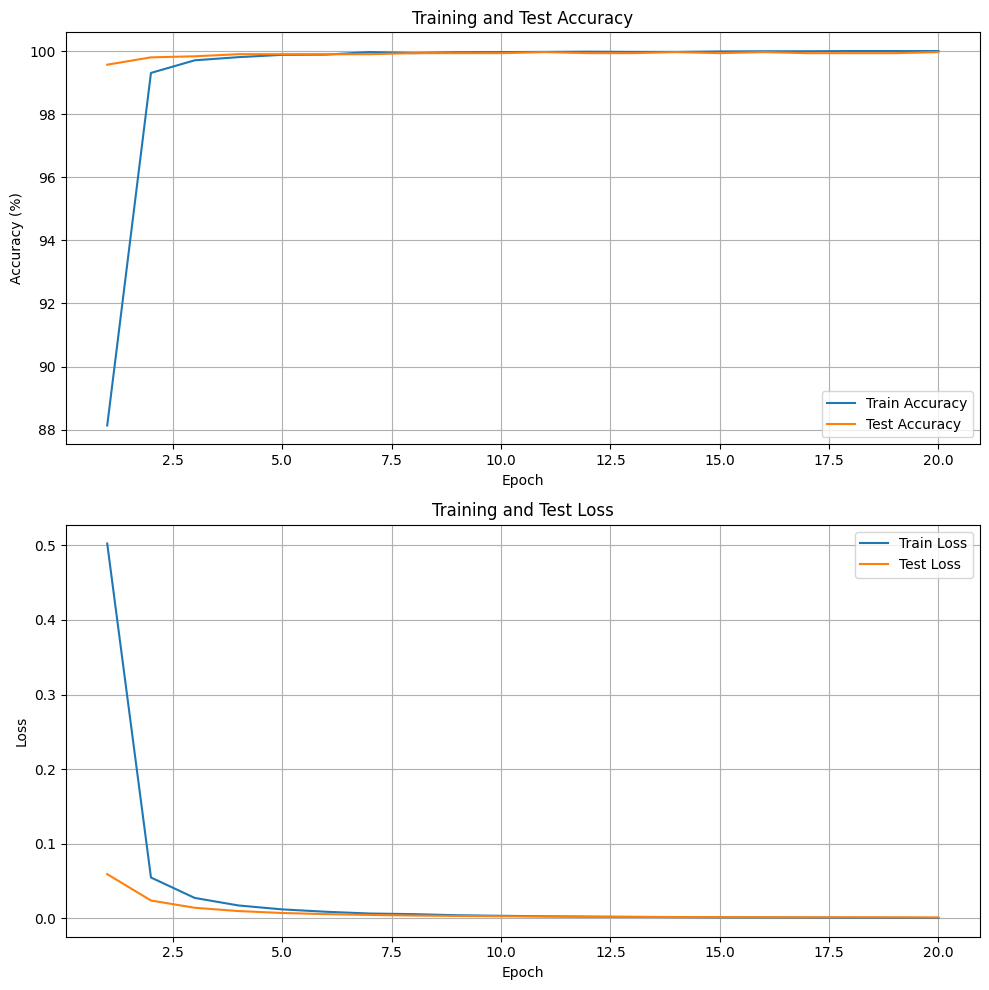

In [32]:
plot_history(history)

## Loading Best Epoch Model and Model Evaluation

During the training loop, we save the best epoch so it can be used for proper evaluation.

In [33]:
cmp_mdl.load_state_dict(best_model_state)

<All keys matched successfully>

In [34]:
evaluation = eval_model(model = cmp_mdl, 
               data_loader = val_embloader, 
               loss_fn = loss_fn, 
               accuracy_fn = accuracy_fn,
              device = device)

evaluation

{'model_name': 'OptimizedModule',
 'model_loss': 0.0025895440435790003,
 'model_acc': 99.96675531914893}

## Building Confusion Matrix

The confusion matrix shows which vegetables the model confuses with each other. The diagonal is correct predictions; everything else is a mistake.

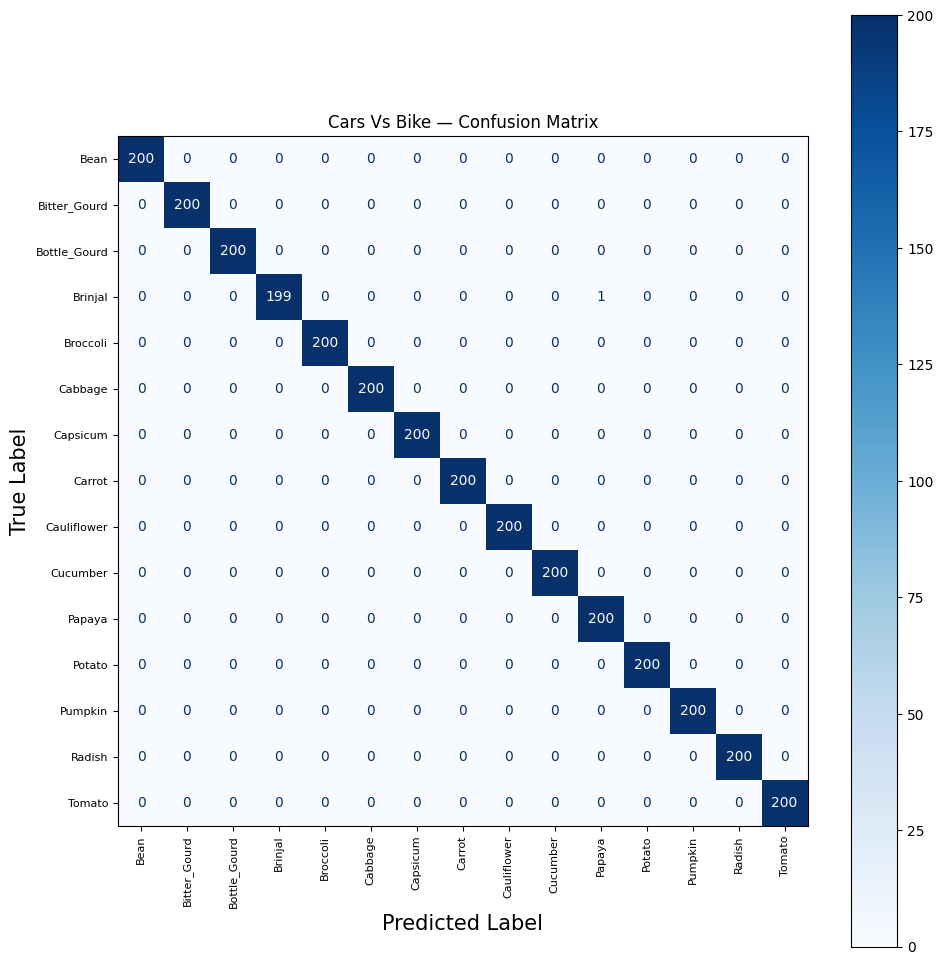

In [35]:
all_preds, all_labels = [], []

cmp_mdl.eval()
with torch.no_grad():
    for x, y in val_embloader:
        x = x.to(device)
        preds = cmp_mdl(x).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "Cars Vs Bike — Confusion Matrix",
)

ax.set_xlabel("Predicted Label", fontsize=15)
ax.set_ylabel("True Label", fontsize=15)

# Smaller class-name font
plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center",
    fontsize=8
)

plt.setp(
    ax.get_yticklabels(),
    fontsize=8
)

plt.tight_layout()
plt.show()


## Classification Report

The report shows Precision, Recall and F1 Score for every class, and also includes the `Macro Avg`.

Macro Avg calculates a metric (like precision, recall or F1-score) for each class independently and then takes the unweighted mean of those scores. Because it treats every class equally regardless of how many samples it contains, it is highly sensitive to the performance of weak or rare classes.

In [36]:
# 1. Define an evaluation step function for the Ignite Engine
def evaluate_step(engine, batch):
    cmp_mdl.eval()
    with torch.no_grad():
        x, y = batch
        x, y = x.to(device), y.to(device)
        output = cmp_mdl(x)
        y_pred = output[1] if isinstance(output, tuple) else output
        return y_pred, y

evaluator = Engine(evaluate_step)

# 2. Attach the metric handler to your engine
# target_names is an optional list of string labels
cr = ClassificationReport(labels=class_names)
cr.attach(evaluator, "classification_report")

# 3. Run evaluation over your PyTorch DataLoader
state = evaluator.run(val_embloader)

# 4. Extract and print results
state.metrics["classification_report"]


'{"Bean": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Bitter_Gourd": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Bottle_Gourd": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Brinjal": {"precision": 1.0, "recall": 0.995, "f1-score": 0.997493734335839}, "Broccoli": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Cabbage": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Capsicum": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Carrot": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Cauliflower": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Cucumber": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Papaya": {"precision": 0.9950248756218906, "recall": 1.0, "f1-score": 0.9975062344139646}, "Potato": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Pumpkin": {"precision": 1.0, "reca

## Final Training on Train + Validation Data

Now we complete our model by combining the train data and the validation data, and we evaluate it with the test data. Since the embeddings of `trainval` are already prepared, we only need to:

1. Create a **fresh** classifier. We do not continue from the previous one, otherwise it would have already seen the training data for 20 epochs.
2. Create a new loss function and optimizer.
3. Train and check the result.

In [37]:
torch.manual_seed(42)

trainval_dataset = TensorDataset(
    data["trainval"]["embeddings"],
    data["trainval"]["labels"]
)

trainval_embloader= create_dataloaders(trainval_dataset,  
                                     batch_size=32, 
                                     num_workers=4)

train_dataloader: 563 batches of 32


In [38]:
## Loss Function
loss_fn = nn.CrossEntropyLoss()

## Optimizer
optimizer = AdamW(
    lr= 1e-4,
    params= cmp_mdl.parameters()
)

## Train Model and Plotting Curves

We train the model with train + val data combined, evaluate it with the test data, and check the performance by plotting the curves.

**Note**: `fit_model()` picks the best epoch using the test data here, so the test score can be slightly optimistic. The validation experiment above is the cleaner measurement of generalization.

In [39]:
## Using pytorch_utils fit_model method to train our loop
history, best_model_state = fit_model(model=cmp_mdl,
                                      train_model=train_model,
                                      test_model=test_model,
                                      train_dataloader=trainval_embloader,
                                      test_dataloader=test_embloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      accuracy_fn=accuracy_fn,
                                      epochs=20,
                                      device=device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1
----------


  0%|          | 0/563 [00:00<?, ?it/s]

Train Loss = 0.00224 || Train Accuracy = 99.97%
Test loss: 0.00311 | Test accuracy: 99.90%

🔥 New best model! Accuracy: 99.90%
Epoch 2
----------


  0%|          | 0/563 [00:00<?, ?it/s]

Train Loss = 0.00164 || Train Accuracy = 99.98%
Test loss: 0.00274 | Test accuracy: 99.90%

Epoch 3
----------


... (20 outputs left out)

  0%|          | 0/563 [00:00<?, ?it/s]

Train Loss = 0.00014 || Train Accuracy = 100.00%
Test loss: 0.00240 | Test accuracy: 99.93%

Epoch 20
----------


  0%|          | 0/563 [00:00<?, ?it/s]

Train Loss = 0.00008 || Train Accuracy = 100.00%
Test loss: 0.00281 | Test accuracy: 99.93%

Time Taken on cuda device is 47.212 seconds


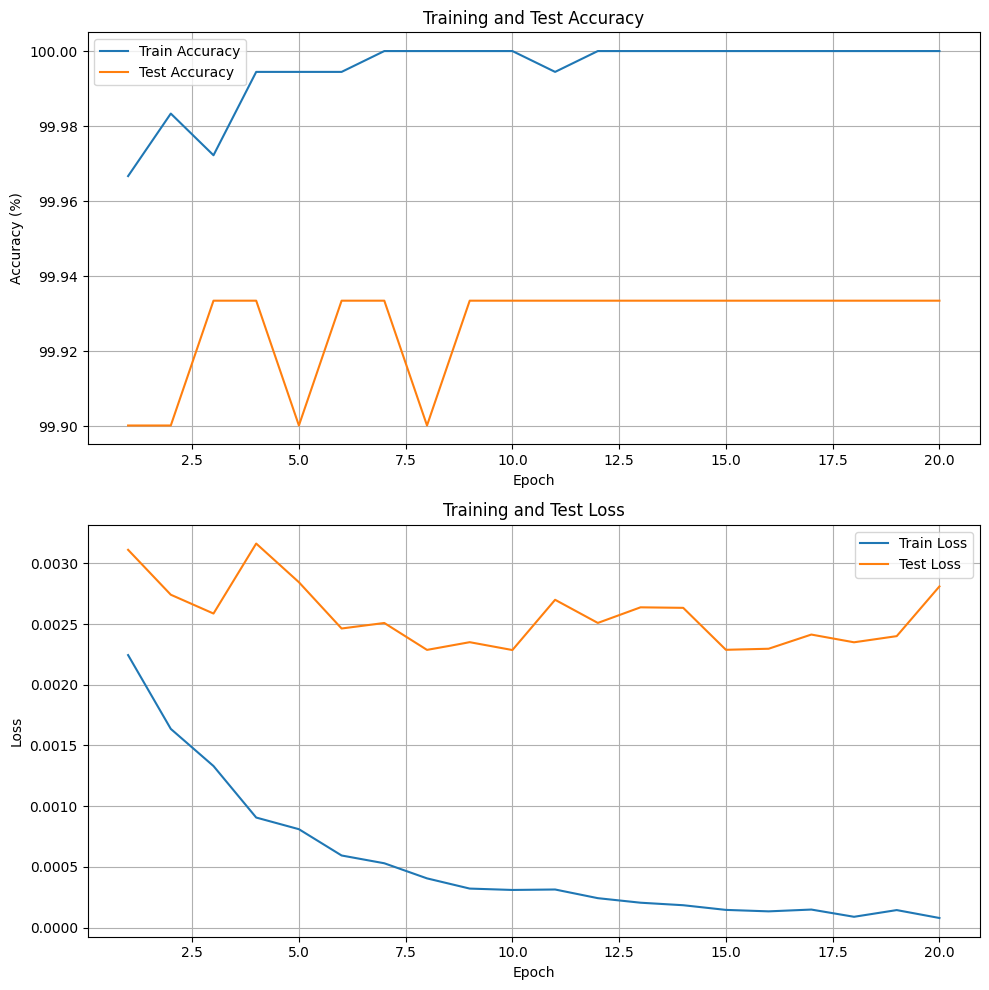

In [40]:
plot_history(history)

## Final Model Evaluation, Confusion Matrix and Classification Report

In [41]:
## Load bets model
cmp_mdl.load_state_dict(best_model_state)

evaluation = eval_model(model = cmp_mdl, 
               data_loader = test_embloader, 
               loss_fn = loss_fn, 
               accuracy_fn = accuracy_fn,
              device = device)

evaluation

{'model_name': 'OptimizedModule',
 'model_loss': 0.0025868906461177987,
 'model_acc': 99.93351063829788}

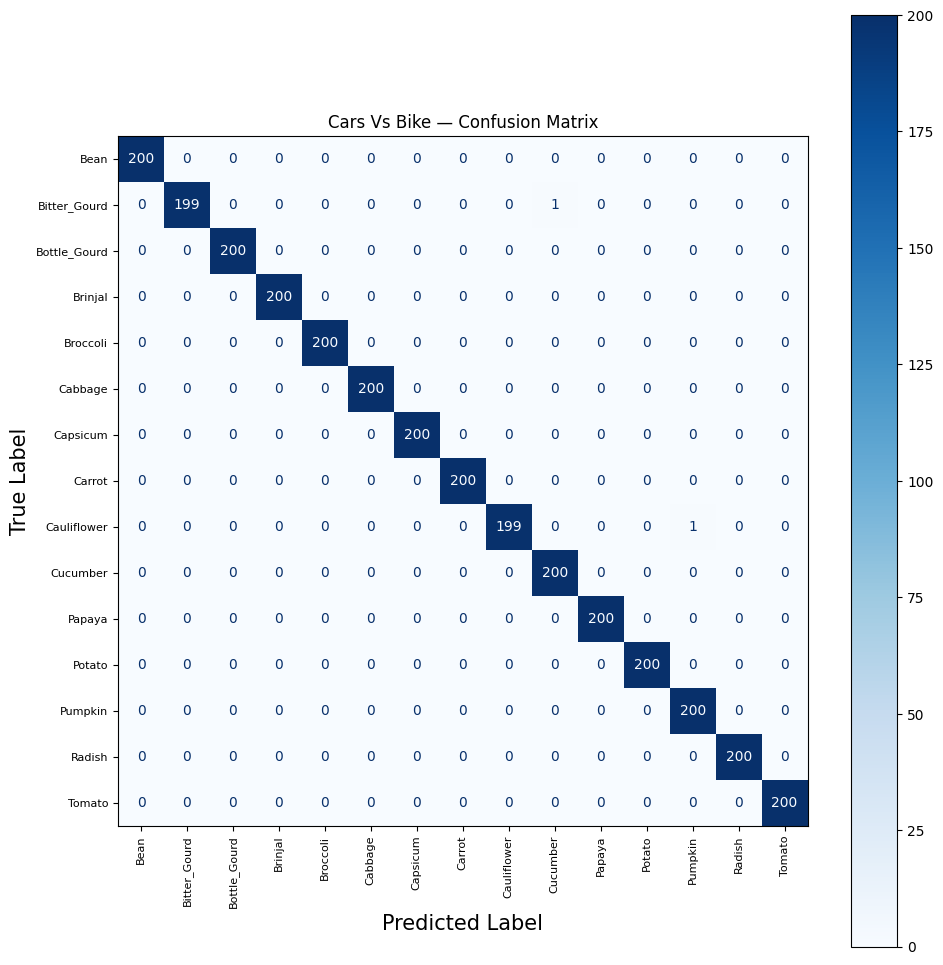

In [42]:
all_preds, all_labels = [], []

cmp_mdl.eval()
with torch.no_grad():
    for x, y in test_embloader:
        x = x.to(device)
        preds = cmp_mdl(x).argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(10, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "Cars Vs Bike — Confusion Matrix",
)

ax.set_xlabel("Predicted Label", fontsize=15)
ax.set_ylabel("True Label", fontsize=15)

# Smaller class-name font
plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center",
    fontsize=8
)

plt.setp(
    ax.get_yticklabels(),
    fontsize=8
)

plt.tight_layout()
plt.show()


In [43]:
# 1. Define an evaluation step function for the Ignite Engine
def evaluate_step(engine, batch):
    cmp_mdl.eval()
    with torch.no_grad():
        x, y = batch
        x, y = x.to(device), y.to(device)
        output = cmp_mdl(x)
        y_pred = output[1] if isinstance(output, tuple) else output
        return y_pred, y

evaluator = Engine(evaluate_step)

# 2. Attach the metric handler to your engine
# target_names is an optional list of string labels
cr = ClassificationReport(labels=class_names)
cr.attach(evaluator, "classification_report")

# 3. Run evaluation over your PyTorch DataLoader
state = evaluator.run(test_embloader)

# 4. Extract and print results
state.metrics["classification_report"]


'{"Bean": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Bitter_Gourd": {"precision": 1.0, "recall": 0.995, "f1-score": 0.997493734335839}, "Bottle_Gourd": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Brinjal": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Broccoli": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Cabbage": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Capsicum": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Carrot": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Cauliflower": {"precision": 1.0, "recall": 0.995, "f1-score": 0.997493734335839}, "Cucumber": {"precision": 0.9950248756218906, "recall": 1.0, "f1-score": 0.9975062344139646}, "Papaya": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Potato": {"precision": 1.0, "recall": 1.0, "f1-score": 0.9999999999999996}, "Pumpkin": {"precision": 0.9950248

## Saving the Model

Now it's time to save the model. We only save the classifier head, because the DINOv2 backbone is unchanged and can always be loaded again from HuggingFace.

In [44]:
## Using torch.save()
torch.save(best_model_state, 'dinov2_custom_classifier.pt')
print("Model Saved Successfully")

Model Saved Successfully
